# Foundation models for time series: Chronos against ETS and ARIMA on macro data

**Objective:** time series foundation models (pretrained on millions of series, used "zero-shot" without training) are now part of the toolbox of many data teams. Are they better than the classical models for the macroeconomic series that a bank or an asset manager forecasts every month? We compare, with the same rolling backtest:

- **Naive** (random walk), the benchmark
- **ETS** (exponential smoothing, damped trend) and **ARIMA** (order chosen by AIC), fitted on each window
- **Chronos-Bolt small** (48 million parameters) and **Chronos-2** (120 million), from Amazon, zero-shot

on 16 monthly series of FRED (US, euro area and France: prices, labour market, activity, rates, exchange rate), with point accuracy (MASE), probabilistic accuracy (weighted quantile loss) and coverage of the 80% intervals, in a calm period (2023-2026) and in the 2021-2022 inflation shock.

**Data:** FRED, Federal Reserve Bank of St. Louis (`download_fred.py`).

Libraries of the project: `pandas`, `numpy`, `statsmodels`, `torch`, `chronos-forecasting`, `matplotlib` and `seaborn`.

## Part 1. Libraries and data

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.stats import norm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from chronos import BaseChronosPipeline, Chronos2Pipeline

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
torch.set_num_threads(4)

fred = pd.read_csv("data/fred_monthly.csv", parse_dates=["date"])
nombres = fred.drop_duplicates("series").set_index("series")["name"]
series = {s: g.set_index("date")["value"].asfreq("MS").interpolate() for s, g in fred.groupby("series")}
print("Series:", len(series))
nombres

Series: 16


series
CPIAUCSL                          US consumer prices (CPI)
PCEPI                                   US PCE price index
UNRATE                                US unemployment rate
PAYEMS                                 US nonfarm payrolls
INDPRO                            US industrial production
RSAFS                                      US retail sales
HOUST                                    US housing starts
M2SL                                    US money supply M2
UMCSENT                   US consumer sentiment (Michigan)
GS10                             US 10-year Treasury yield
FEDFUNDS                                    Fed funds rate
EXUSEU                                     Dollar per euro
CP0000EZ19M086NEST                          Euro area HICP
LRHUTTTTFRM156S                   France unemployment rate
IRLTLT01FRM156N       France 10-year government bond yield
CSUSHPISA                   US house prices (Case-Shiller)
Name: name, dtype: str

## Part 2. The backtest

For each series and each forecast origin we use the last 30 years of history (at most) and forecast the next 12 months. Two evaluation windows:

- **calm:** 9 origins every 3 months, the last one 12 months before the end of the data (forecasts for 2023 to 2026)
- **shock:** 5 origins from January 2021 to January 2022, the months when inflation and rates surprised everybody

In [2]:
H = 12
CONTEXTO = 360
Q = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

tareas = []
for s, y in series.items():
    for i in range(9):
        fin = len(y) - H - 3 * i
        tareas.append({"series": s, "window": "calm", "origin": y.index[fin - 1], "fin": fin})
    for o in pd.date_range("2021-01-01", "2022-01-01", freq="3MS"):
        if o in y.index:
            tareas.append({"series": s, "window": "shock", "origin": o, "fin": y.index.get_loc(o) + 1})
tareas = pd.DataFrame(tareas)
print("Forecasts per model:", len(tareas))
tareas.groupby("window").size()

Forecasts per model: 224


window
calm     144
shock     80
dtype: int64

## Part 3. The models

Every model returns the 9 quantiles (10% to 90%) of each of the 12 months ahead. For ETS the quantiles come from 500 simulated paths; for ARIMA and the naive model from the normal distribution of the forecast errors.

In [3]:
def f_naive(x):
    sd = np.diff(x).std()
    h = np.arange(1, H + 1)
    return np.array([x[-1] + norm.ppf(q) * sd * np.sqrt(h) for q in Q]).T

def f_ets(x):
    m = ETSModel(pd.Series(x), error="add", trend="add", damped_trend=True).fit(disp=False)
    sims = m.simulate(nsimulations=H, repetitions=500, anchor="end").values
    return np.quantile(sims, Q, axis=1).T

def f_arima(x):
    mejor = None
    for p in range(3):
        for q in range(3):
            try:
                m = SARIMAX(x, order=(p, 1, q), trend="c").fit(disp=False)
            except Exception:
                continue
            if mejor is None or m.aic < mejor.aic:
                mejor = m
    fc = mejor.get_forecast(H)
    return np.array([fc.predicted_mean + norm.ppf(q) * fc.se_mean for q in Q]).T

bolt = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
c2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu", torch_dtype=torch.float32)

def f_bolt(xs):
    q, _ = bolt.predict_quantiles([torch.tensor(x, dtype=torch.float32) for x in xs], prediction_length=H, quantile_levels=Q)
    return [qi.numpy() for qi in q]

def f_chronos2(xs):
    q, _ = c2.predict_quantiles([np.asarray(x, dtype=np.float32) for x in xs], prediction_length=H, quantile_levels=Q)
    return [qi[0].numpy() for qi in q]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 27789.72it/s]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 7/170 [00:00<00:02, 57.16it/s]

Loading weights:   8%|▊         | 13/170 [00:00<00:02, 55.33it/s]

Loading weights:  11%|█         | 19/170 [00:00<00:03, 44.02it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 373.70it/s]

In [4]:
contextos = [series[t.series].values[max(0, t.fin - CONTEXTO):t.fin] for t in tareas.itertuples()]
reales = [series[t.series].values[t.fin:t.fin + H] for t in tareas.itertuples()]
# the forecasts of each model are saved, so the notebook can be run again without repeating them
import pickle
os.makedirs("data/forecasts", exist_ok=True)
pred, tiempos = {}, {}
modelos = [("naive", f_naive, False), ("ETS", f_ets, False), ("ARIMA", f_arima, False), ("Chronos-Bolt small", f_bolt, True), ("Chronos-2", f_chronos2, True)]
for nombre, f, por_lotes in modelos:
    ruta = f"data/forecasts/{nombre.replace(' ', '_')}.pkl"
    if os.path.exists(ruta):
        pred[nombre], tiempos[nombre] = pickle.load(open(ruta, "rb"))
        continue
    t0 = time.perf_counter()
    if por_lotes:
        pred[nombre] = sum([f(contextos[i:i + 32]) for i in range(0, len(contextos), 32)], [])
    else:
        pred[nombre] = [f(x) for x in contextos]
    tiempos[nombre] = time.perf_counter() - t0
    pickle.dump((pred[nombre], tiempos[nombre]), open(ruta, "wb"))
pd.Series(tiempos, name="seconds for all the forecasts").round(1)

naive                   0.1
ETS                     3.4
ARIMA                 194.5
Chronos-Bolt small      2.0
Chronos-2               9.4
Name: seconds for all the forecasts, dtype: float64

## Part 4. Metrics

- **MASE:** mean absolute error of the median forecast divided by the mean absolute 1-month change of the series in its context (1 = as bad as a naive forecast made inside the sample)
- **WQL:** weighted quantile loss, the average pinball loss of the 9 quantiles divided by the size of the series. It rewards good intervals, not only a good median
- **Coverage 80%:** share of the real values inside the 10%-90% interval (should be 80%)

In [5]:
def metricas(qf, y, x):
    escala = np.mean(np.abs(np.diff(x)))
    med = qf[:, Q.index(0.5)]
    pin = sum(np.sum(2 * np.maximum(q * (y - qf[:, j]), (q - 1) * (y - qf[:, j]))) for j, q in enumerate(Q)) / len(Q)
    return {"mase": np.mean(np.abs(y - med)) / escala, "wql": pin / np.sum(np.abs(y)),
            "coverage_80": np.mean((y >= qf[:, 0]) & (y <= qf[:, -1])), "abs_err_h": np.abs(y - med) / escala}

filas = []
for nombre, ps in pred.items():
    for t, qf, y, x in zip(tareas.itertuples(), ps, reales, contextos):
        m = metricas(qf, y, x)
        filas.append({"model": nombre, "series": t.series, "window": t.window, "origin": t.origin, **{k: v for k, v in m.items() if k != "abs_err_h"}})
res = pd.DataFrame(filas)

# relative MASE against the naive model, aggregated with the geometric mean (the usual way in the M competitions)
base = res[res["model"] == "naive"].set_index(["series", "window", "origin"])["mase"]
res["rel_mase"] = res["mase"].values / base.reindex(pd.MultiIndex.from_frame(res[["series", "window", "origin"]])).values
resumen = res.groupby(["window", "model"]).agg(mase=("mase", "mean"), rel_mase_geo=("rel_mase", lambda r: np.exp(np.log(r.clip(1e-6)).mean())),
                                              wql=("wql", "mean"), wql_median=("wql", "median"), coverage_80=("coverage_80", "mean"))
resumen.round(3)

mase  rel_mase_geo    wql  wql_median  \
window model                                                         
calm   ARIMA                2.051         0.671  0.032       0.014   
       Chronos-2            2.628         0.794  0.029       0.018   
       Chronos-Bolt small   2.590         0.837  0.030       0.015   
       ETS                  2.577         0.841  0.034       0.017   
       naive                3.563         1.000  0.035       0.018   
shock  ARIMA                7.999         0.888  0.224       0.037   
       Chronos-2            7.422         0.781  0.192       0.035   
       Chronos-Bolt small   6.992         0.747  0.177       0.034   
       ETS                  7.296         0.811  0.195       0.036   
       naive               10.384         1.000  0.189       0.047   

                           coverage_80  
window model                            
calm   ARIMA                     0.939  
       Chronos-2                 0.894  
       Chronos-Bolt small        0.948  
       ETS                       0.925  
       naive                     0.714  
shock  ARIMA                     0.521  
       Chronos-2                 0.634  
       Chronos-Bolt small        0.674  
       ETS                       0.597  
       naive                     0.497

A relative MASE below 1 means the model beats the naive forecast. The WQL is divided by the level of the series, so in the shock window it explodes for the fed funds rate (close to 0% in 2021): the median WQL is more robust. We also count in how many series each model is the best (lowest WQL, average of the origins).

In [6]:
mejor = res.groupby(["window", "series", "model"])["wql"].mean().unstack()
ganadores = mejor.idxmin(axis=1).groupby(level=0).value_counts().unstack(fill_value=0)
ganadores

,ARIMA,Chronos-2,Chronos-Bolt small,ETS,naive
window,,,,,
calm,7,5,2,0,2
shock,0,6,5,5,0


### Error by horizon

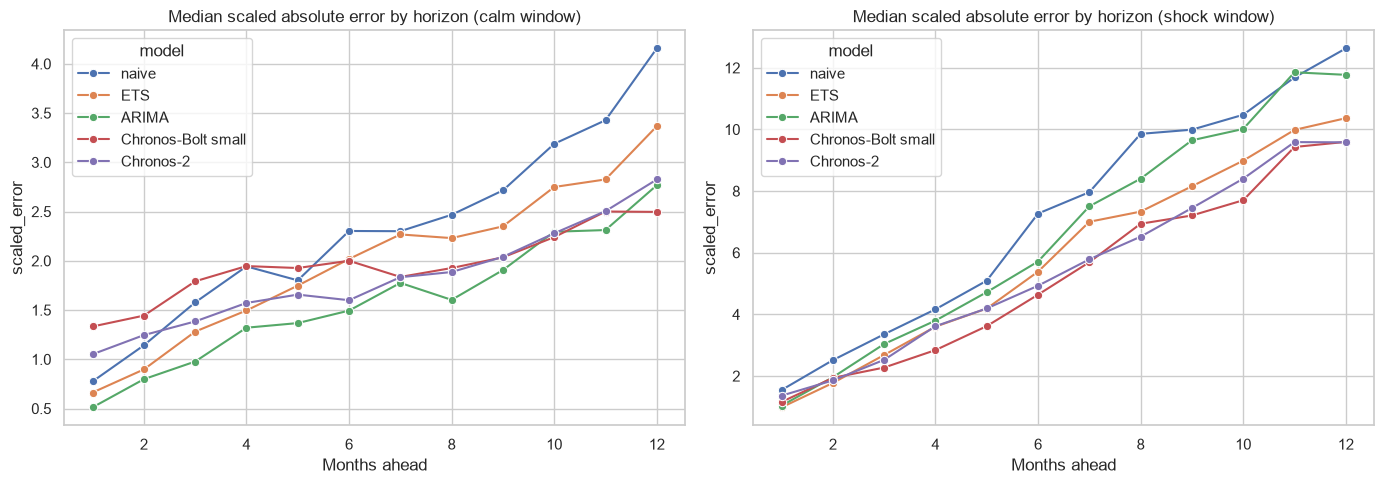

In [7]:
err = []
for nombre, ps in pred.items():
    for t, qf, y, x in zip(tareas.itertuples(), ps, reales, contextos):
        e = metricas(qf, y, x)["abs_err_h"]
        for h, v in enumerate(e, 1):
            err.append({"model": nombre, "window": t.window, "h": h, "scaled_error": v})
err = pd.DataFrame(err)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, w in zip(axes, ["calm", "shock"]):
    sns.lineplot(err[err["window"] == w], x="h", y="scaled_error", hue="model", estimator="median", errorbar=None, marker="o", ax=ax)
    ax.set_title(f"Median scaled absolute error by horizon ({w} window)")
    ax.set_xlabel("Months ahead")
plt.tight_layout()
plt.savefig("figures/error_by_horizon.png", bbox_inches="tight")
plt.show()

### By series

Average WQL of each model in each series (calm window). Colors are relative to the best model of each row.

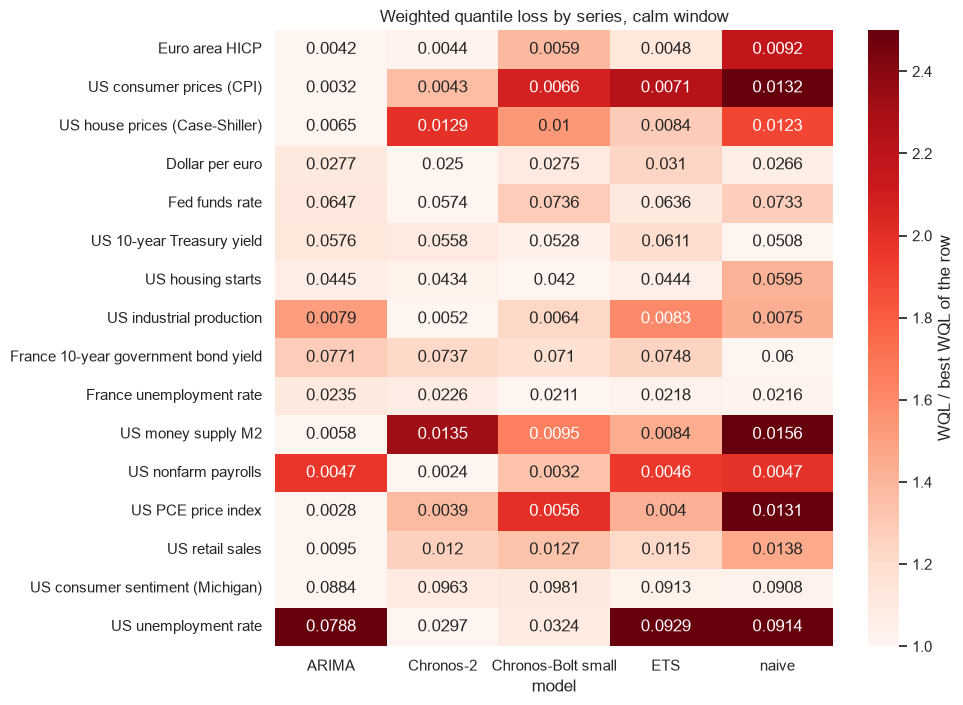

In [8]:
tabla = mejor.loc["calm"].copy()
tabla.index = [nombres[s] for s in tabla.index]
plt.figure(figsize=(9, 8))
sns.heatmap(tabla.div(tabla.min(axis=1), axis=0), annot=tabla.round(4), fmt="", cmap="Reds", vmin=1, vmax=2.5, cbar_kws={"label": "WQL / best WQL of the row"})
plt.title("Weighted quantile loss by series, calm window")
plt.savefig("figures/wql_by_series.png", bbox_inches="tight")
plt.show()

## Part 5. An example: US CPI in 2021

The forecasts made in April 2021, just before inflation went up.

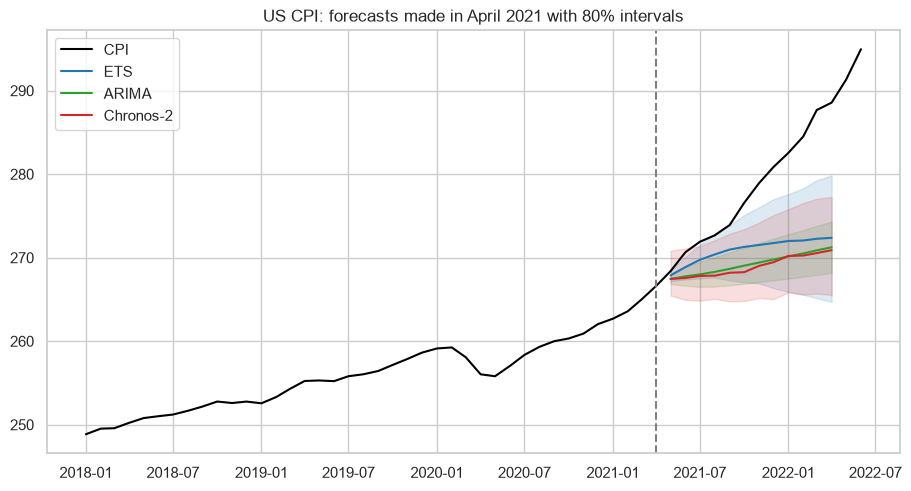

In [9]:
s, o = "CPIAUCSL", pd.Timestamp("2021-04-01")
i = tareas[(tareas["series"] == s) & (tareas["origin"] == o)].index[0]
y = series[s]
fechas = pd.date_range(o + pd.offsets.MonthBegin(1), periods=H, freq="MS")
plt.figure(figsize=(11, 5.5))
plt.plot(y["2018":"2022-06"], color="black", label="CPI")
for nombre, color in [("ETS", "tab:blue"), ("ARIMA", "tab:green"), ("Chronos-2", "tab:red")]:
    qf = pred[nombre][i]
    plt.plot(fechas, qf[:, 4], color=color, label=nombre)
    plt.fill_between(fechas, qf[:, 0], qf[:, -1], color=color, alpha=0.15)
plt.axvline(o, ls="--", color="grey")
plt.title("US CPI: forecasts made in April 2021 with 80% intervals")
plt.legend()
plt.savefig("figures/cpi_2021_example.png", bbox_inches="tight")
plt.show()

None of the models saw the inflation of 2021 coming: in April 2021 all the 80% intervals end far below the CPI of 2022. A model that only looks at the past of the series cannot forecast a change of regime.

## Conclusions

- **In the calm window (2023-2026) ARIMA is the best point forecast:** relative MASE 0.67 against the naive forecast, the best in 7 of the 16 series, and much better in the first months ahead. The two Chronos models beat the naive forecast (0.79 and 0.84) but not ARIMA, and they are the worst at 1 to 3 months.
- **For the intervals the foundation models are competitive:** Chronos-2 has the lowest mean weighted quantile loss in the calm window (0.029), with an 80% interval that covers 89% of the values.
- **In the 2021-2022 shock Chronos is better than the classical models:** Chronos-Bolt has the lowest relative MASE (0.75) and quantile loss, and its intervals cover 67% of the values against 52% for ARIMA. ARIMA, the best in calm times, is the worst of the four models in the shock. All the intervals were too narrow: nobody expected that inflation.
- **Cost:** the two Chronos models make the 224 forecasts of 12 months in 2 and 9 seconds on a laptop CPU, without any fitting; the ARIMA search needs more than 3 minutes.
- **For a forecasting team:** Chronos is a good zero-shot baseline, robust when the series change behaviour, but it does not replace a well specified classical model on stable macro series. Both should be in the benchmark.